# **Envrionment Setup**

In [1]:
# =============================================================
# CELL 1: Environment Setup
# Runtime → Change runtime type → T4 GPU (do this BEFORE running)
# =============================================================

# Unsloth must be installed FIRST (it pulls compatible CUDA kernels).
!pip install -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"

# --no-deps prevents pip from upgrading packages Unsloth pinned.
!pip install -q --no-deps xformers trl peft accelerate bitsandbytes

# -------------------------------------------------------------
# Sanity checks — fail fast before we touch any model
# -------------------------------------------------------------
import sys
import torch

print(f"Python          : {sys.version.split()[0]}")
print(f"PyTorch         : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Go to Runtime → Change runtime type → "
        "Hardware accelerator → T4 GPU, then re-run this cell."
    )

props = torch.cuda.get_device_properties(0)
print(f"GPU             : {props.name}")
print(f"VRAM (GB)       : {props.total_memory / 1e9:.1f}")

# Confirm the four core libs are importable
import transformers, peft, trl, bitsandbytes
print(f"transformers    : {transformers.__version__}")
print(f"peft            : {peft.__version__}")
print(f"trl             : {trl.__version__}")
print(f"bitsandbytes    : {bitsandbytes.__version__}")

# -------------------------------------------------------------
# Verify Unsloth itself imports (fails fast if kernels didn't build)
# -------------------------------------------------------------
try:
    from unsloth import FastLanguageModel
    import unsloth
    print(f"unsloth         : {unsloth.__version__}")
    print("   FastLanguageModel import: ✅")
except Exception as e:
    print(f"unsloth import FAILED: {e}")
    print("\n⚠️  Go to Runtime → Restart session, then jump straight to Cell 2.")
    print("   (You don't need to re-run Cell 1 after restarting.)")
    raise

print("\n✅ Cell 1 complete — environment is ready.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Python          : 3.13.16
PyTorch         : 2.11.0+cu130
CUDA available  : True
GPU             : Tesla T4
VRAM (GB)       : 15.6
transformers    : 5.17.0
peft            : 0.21.2
trl             : 1.15.0
bitsandbytes    : 0.50.2
🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/usr/local/lib/python3.13/dist-packages/unsloth/__init__.py:1666: UserWarning: WARNING: Unsloth should be imported before [trl, transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
unsloth         : 2026.10.10
   FastLanguageModel import: ✅

✅ Cell 1 complete — environment is ready.


# **Dataset Loading & Split**

In [2]:
# =============================================================
# CELL 2: Dataset Loading & Split
# =============================================================
# Uses cardiffnlp/tweet_eval (sentiment config):
#   Full split: 45,686 train / 2,000 validation / 12,284 test
#   3 classes: 0 = negative, 1 = neutral, 2 = positive
#   NOTE: the test set is class-IMBALANCED (~48% neutral). This is
#         expected — it's how the dataset maintainers published it.
#         Do not "fix" it by rebalancing; report majority baseline
#         in Cell 6 to contextualize accuracy.
#
# Domain-matching alternative (financial text) — uncomment to try:
#   raw = load_dataset("takala/financial_phrasebank", "sentences_allagree",
#                      trust_remote_code=True)
#   # NOTE: only 'train' split exists (n=2,264) → manual split required
# =============================================================

from datasets import load_dataset
from collections import Counter

LABELS = ["negative", "neutral", "positive"]   # index = HF label integer

raw = load_dataset("cardiffnlp/tweet_eval", "sentiment")

def to_sft(example):
    """Map a raw example into the (instruction, input, output) SFT schema
    that the formatting_func in Cell 4 expects."""
    return {
        "instruction": "Classify the sentiment of the following text as negative, neutral, or positive.",
        "input": example["text"].strip(),
        "output": LABELS[example["label"]],
    }

train_ds = raw["train"].map(to_sft, remove_columns=["text", "label"])
val_ds   = raw["validation"].map(to_sft, remove_columns=["text", "label"])
test_ds  = raw["test"].map(to_sft, remove_columns=["text", "label"])

# --- Optional: subsample train for Colab free tier -------------------
# 5,000 examples ≈ ~38 min of LoRA training on a T4 (batch=2, accum=4,
# ~625 steps). Set to None for the full 45,686 (adds ~5 more hours).
TRAIN_SUBSET = 5000
if TRAIN_SUBSET is not None:
    train_ds = train_ds.shuffle(seed=42).select(range(min(TRAIN_SUBSET, len(train_ds))))

# -------------------------------------------------------------
# SANITY GATES — if any of these fail, DO NOT trust downstream metrics
# -------------------------------------------------------------
print(f"Train: {len(train_ds):>5}   Val: {len(val_ds):>4}   Test: {len(test_ds):>5}")
print("Train classes:", dict(Counter(train_ds["output"])))
print("Val   classes:", dict(Counter(val_ds["output"])))
print("Test  classes:", dict(Counter(test_ds["output"])))

assert len(test_ds) >= 500,  f"Test set too small: {len(test_ds)}"
assert len(set(test_ds["output"])) == 3, "Test set is missing one or more classes"
for label in LABELS:
    n = test_ds["output"].count(label)
    assert n >= 100, f"Class '{label}' has only {n} test examples — metrics will be unstable"

# Document the imbalance so it's not mistaken for a bug
test_counts = Counter(test_ds["output"])
majority_share = test_counts.most_common(1)[0][1] / len(test_ds)
print(f"\nTest majority-class share: {majority_share:.1%} "
      f"({test_counts.most_common(1)[0][0]}) — expected for this dataset")

# -------------------------------------------------------------
# Peek at one example — verify the format matches what Cell 4 expects
# -------------------------------------------------------------
i = 0
print("\n--- Sample ---")
print("instruction:", train_ds[i]["instruction"])
print("input      :", train_ds[i]["input"][:120], "..." if len(train_ds[i]["input"]) > 120 else "")
print("output     :", train_ds[i]["output"])

print("\n✅ Cell 2 complete — dataset ready for Cell 3")

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/45615 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12284 [00:00<?, ? examples/s]

Train:  5000   Val: 2000   Test: 12284
Train classes: {'positive': 1956, 'negative': 775, 'neutral': 2269}
Val   classes: {'neutral': 869, 'positive': 819, 'negative': 312}
Test  classes: {'neutral': 5937, 'positive': 2375, 'negative': 3972}

Test majority-class share: 48.3% (neutral) — expected for this dataset

--- Sample ---
instruction: Classify the sentiment of the following text as negative, neutral, or positive.
input      : Few more hours to iPhone 6s launch and im still using the 4th generation ^_^ 
output     : positive

✅ Cell 2 complete — dataset ready for Cell 3


# **Load Base Model (4-bit) + Attach LoRA Adapter**

In [3]:
# =============================================================
# CELL 3: Load Base Model (4-bit) + Attach LoRA Adapter
# =============================================================

import torch
from unsloth import FastLanguageModel

# --- 0. Free any leftover VRAM from a previous session -------
torch.cuda.empty_cache()

# --- 1. Load the base model in 4-bit -------------------------
# Pinned Unsloth ID — the bare "unsloth/mistral-7b" may not resolve
# in future Unsloth releases.
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name    = "unsloth/mistral-7b-bnb-4bit",
    max_seq_length= 1024,          # matches Cell 4 SFTTrainer
    dtype         = None,          # auto: fp16 on T4 (Turing), bf16 on Ampere+
    load_in_4bit  = True,
)

# --- 2. Attach the LoRA adapter ------------------------------
# Full 7-module targeting gives Mistral-7B enough capacity to adapt.
# Restricting to only q_proj/v_proj often underfits on downstream tasks.
model = FastLanguageModel.get_peft_model(
    model,
    r              = 16,                            # LoRA rank
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj"],
    lora_alpha     = 16,                            # scaling = alpha / r = 1
    lora_dropout   = 0.0,                           # Unsloth recommends 0 for speed
    bias           = "none",
    use_gradient_checkpointing = "unsloth",         # memory saving
    random_state   = 3407,                          # matches Cell 4 seed
)

# --- 3. Silence the max_length vs max_new_tokens warning ----
# Base model inherits a huge max_length (32,768). Setting it to None
# lets max_new_tokens in Cell 5 take full control cleanly.
model.generation_config.max_length = None

# --- 4. Sanity checks ----------------------------------------
trainable, total = model.get_nb_trainable_parameters()
print(f"Trainable params : {trainable:,}  ({100 * trainable / total:.2f}% of total)")
print(f"Total params     : {total:,}")
assert trainable < 0.05 * total, "LoRA should train <5% of parameters — check target_modules"
assert trainable > 1_000_000,   "LoRA adapter suspiciously small — check target_modules"

# --- 5. Smoke test -------------------------------------------
# This is a COMPLETION model (not instruct-tuned), so it will *autocomplete*
# the prompt rather than answer it. Any non-empty output = pipeline works.
# We are NOT testing answer quality here — that's Cell 5's job.
FastLanguageModel.for_inference(model)
_test_prompt = "### Instruction:\nSay 'hello'.\n\n### Response:\n"
_ids  = tokenizer(_test_prompt, return_tensors="pt").to("cuda")
_out  = model.generate(**_ids, max_new_tokens=16, do_sample=False,
                       pad_token_id=tokenizer.eos_token_id)
_completion = tokenizer.decode(_out[0][_ids["input_ids"].shape[-1]:],
                               skip_special_tokens=True)
print(f"Smoke test      : {_completion!r}")
print("   (completion model — expect rambling, not a clean 'hello')")

print("\n✅ Cell 3 complete — base model + LoRA adapter ready")

==((====))==  Unsloth 2026.10.10: Fast Mistral patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Unsloth 2026.10.10 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


Unsloth: compiling each transformer block as one region (MistralDecoderLayer).
Trainable params : 41,943,040  (0.58% of total)
Total params     : 7,283,675,136
Smoke test      : "Hello!\n\n### Instruction:\nSay 'hello' again."
   (completion model — expect rambling, not a clean 'hello')

✅ Cell 3 complete — base model + LoRA adapter ready


# **Training Loop (SFTTrainer) + Save Adapter**

In [4]:
# =============================================================
# CELL 4: Training Loop (SFTTrainer) + Save Adapter
# Expected runtime on T4: ~38 min for 5,000 examples
# =============================================================

import torch, time
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

# --- 1. Prompt formatting function ---------------------------
# SFTTrainer runs this over batches of *examples* (via .map), returning
# a list of fully-formatted strings. Keeping the template explicit
# avoids the silent misalignment that `dataset_text_field` can cause.
def formatting_prompts_func(examples):
    texts = []
    for ins, inp, out in zip(examples["instruction"],
                              examples["input"],
                              examples["output"]):
        texts.append(
            "Below is an instruction that describes a task, paired with an "
            "input that provides further context. Write a response that "
            "appropriately completes the request.\n\n"
            f"### Instruction:\n{ins}\n\n"
            f"### Input:\n{inp}\n\n"
            f"### Response:\n{out}"
        )
    return texts

# --- 2. Sanity check before training ------------------------
assert len(train_ds) >= 1000, f"Training set too small ({len(train_ds)}). Check Cell 2."
print(f"Training on {len(train_ds):,} examples")
print(f"Sample (first 200 chars):\n{formatting_prompts_func(train_ds[:1])[0][:200]}...\n")

# --- 3. Configure training arguments ------------------------
# 1 epoch on 5,000 examples ≈ 625 steps ≈ 38 min on T4.
# NOTE: training loss will plateau around ~0.9 by step 140 — that is
# NORMAL for a 3-class single-token task. Do NOT increase epochs;
# more epochs overfit (train loss ↓, test accuracy ↓).
training_args = TrainingArguments(
    per_device_train_batch_size = 2,
    gradient_accumulation_steps = 4,      # effective batch size = 8
    warmup_steps                = 10,
    num_train_epochs            = 1,
    learning_rate               = 2e-4,
    fp16                        = not is_bfloat16_supported(),
    bf16                        = is_bfloat16_supported(),
    logging_steps               = 10,
    optim                       = "adamw_8bit",   # memory-efficient
    weight_decay                = 0.01,
    lr_scheduler_type           = "linear",
    seed                        = 3407,
    output_dir                  = "./lora_output",
    report_to                   = "none",
    save_strategy               = "no",
)

# --- 4. Build and run the trainer ---------------------------
# (`tokenizer=` is deprecated in newer TRL — a warning may appear,
#  but the argument still works and matches what ran today.)
trainer = SFTTrainer(
    model           = model,
    tokenizer       = tokenizer,
    train_dataset   = train_ds,
    formatting_func = formatting_prompts_func,
    max_seq_length  = 1024,
    args            = training_args,
)

print("\n🚀 Starting training...")
start   = time.time()
trainer.train()
elapsed = time.time() - start
print(f"\n✅ Training finished in {elapsed/60:.1f} minutes")

# --- 5. SAVE THE ADAPTER  ⚠️ CRITICAL -------------------------
# If Colab disconnects during Cell 5 (~25 min), this is your recovery.
# Reload in a fresh session with:
#     model.load_adapter("lora_adapter")
model.save_pretrained("lora_adapter")
tokenizer.save_pretrained("lora_adapter")
print("✅ Adapter saved to ./lora_adapter")

# --- 6. Post-training sanity check --------------------------
try:
    trainer.model.print_trainable_parameters()
except Exception:
    trainable, total = model.get_nb_trainable_parameters()
    print(f"trainable params: {trainable:,} || all params: {total:,} "
          f"|| trainable%: {100*trainable/total:.4f}")

# Free fragmented VRAM so Cell 5's batch inference has room
torch.cuda.empty_cache()
print("\n✅ Cell 4 complete — proceed to Cell 5")

Training on 5,000 examples
Sample (first 200 chars):
Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
Classify the sentiment o...



Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.

🚀 Starting training...


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 5,000 | Num Epochs = 1 | Total steps = 625
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 7,283,675,136 (0.58% trained)


Step,Training Loss
10,1.890954
20,1.147440
30,1.070746
40,0.976628
50,1.020399
60,0.973038
70,0.973819
80,0.973157
90,1.009076


Step,Training Loss
10,1.890954
20,1.147440
30,1.070746
40,0.976628
50,1.020399
60,0.973038
70,0.973819
80,0.973157
90,1.009076
100,0.942665


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!

✅ Training finished in 35.2 minutes


Unsloth: Restored added_tokens_decoder metadata in lora_adapter/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in lora_adapter.


✅ Adapter saved to ./lora_adapter
trainable params: 41,943,040 || all params: 7,283,675,136 || trainable%: 0.5758

✅ Cell 4 complete — proceed to Cell 5


# **Run Inference (Base + LoRA), save raw outputs**

In [5]:
# =============================================================
# CELL 5A: Run Inference (Base + LoRA), save raw outputs
# =============================================================
# ⚠️ This cell takes ~25 min on T4 (12 min per pass). It saves raw
# completions to ./lora_results.pkl so Cell 5B can be re-run infinitely
# without re-inferring (e.g., if you tweak the parser or metrics).
# =============================================================
import torch, pickle, time
from collections import Counter

# --- 1. Prompt builder — identical to Cell 4 training template
def build_prompt(ex):
    return (
        "Below is an instruction that describes a task, paired with an "
        "input that provides further context. Write a response that "
        "appropriately completes the request.\n\n"
        f"### Instruction:\n{ex['instruction']}\n\n"
        f"### Input:\n{ex['input']}\n\n"
        f"### Response:\n"
    )

# --- 2. Batch inference — returns RAW completions (no parsing yet)
tokenizer.padding_side = "left"

@torch.no_grad()
def run_inference(model, tokenizer, prompts, batch_size=32, tag=""):
    FastLanguageModel.for_inference(model)
    completions = []
    t0 = time.time()
    for i in range(0, len(prompts), batch_size):
        batch = prompts[i:i + batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding=True,
                           truncation=True, max_length=512).to("cuda")
        out = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )
        L = inputs["input_ids"].shape[1]
        for j in range(len(batch)):
            completions.append(
                tokenizer.decode(out[j][L:], skip_special_tokens=True).strip()
            )
        if (i // batch_size) % 50 == 0:
            print(f"  [{tag}] ... {i + len(batch):>5}/{len(prompts)}  "
                  f"({time.time()-t0:.0f}s elapsed)")
    return completions

# --- 3. Build prompts + labels
test_prompts = [build_prompt(ex) for ex in test_ds]
y_true       = [ex["output"] for ex in test_ds]
print(f"Test set: {len(y_true):,} examples")

# --- 4. Verify adapter is attached (version-robust check)
FastLanguageModel.for_inference(model)
def _active_adapters(m):
    if not hasattr(m, "active_adapters"):
        return None
    v = m.active_adapters
    return v() if callable(v) else v
active = _active_adapters(model)
print(f"Active adapters: {active}")
if not active:
    n_lora = sum(1 for k in model.state_dict() if "lora_" in k)
    print(f"LoRA tensors in state_dict: {n_lora}")
    assert n_lora > 0, "No LoRA weights found — Cells 3/4 did not attach an adapter"

# --- 5. Run BASE (adapter disabled) then LoRA (adapter active)
t0 = time.time()
print("\n▶ BASE model (adapter disabled)...")
with model.disable_adapter():
    base_raw = run_inference(model, tokenizer, test_prompts, tag="base")

print("\n▶ LoRA model (adapter active)...")
lora_raw = run_inference(model, tokenizer, test_prompts, tag="lora")
print(f"\n✅ Inference complete in {(time.time()-t0)/60:.1f} min")

# --- 6. Save to disk ⚠️ CRITICAL — recover here if Cell 5B has issues
results = {
    "y_true":    y_true,
    "base_raw":  base_raw,
    "lora_raw":  lora_raw,
    "n_examples": len(y_true),
}
with open("lora_results.pkl", "wb") as f:
    pickle.dump(results, f)
print("💾 Saved → ./lora_results.pkl  "
      "(rerun Cell 5B without re-inferring)")

# --- 7. Quick preview  (not an assertion — base being unparseable
#      is the finding, not a bug)
print("\nQuick preview:")
print(f"  Base completions — non-empty: "
      f"{sum(1 for c in base_raw if c)}/{len(base_raw)}")
print(f"  LoRA completions — non-empty: "
      f"{sum(1 for c in lora_raw if c)}/{len(lora_raw)}")
print(f"  Base raw sample : {base_raw[:2]}")
print(f"  LoRA raw sample : {lora_raw[:2]}")

print("\n✅ Cell 5A complete — proceed to Cell 5B")

Test set: 12,284 examples
Active adapters: ['default']

▶ BASE model (adapter disabled)...
  [base] ...    32/12284  (4s elapsed)
  [base] ...  1632/12284  (214s elapsed)
  [base] ...  3232/12284  (421s elapsed)
  [base] ...  4832/12284  (631s elapsed)
  [base] ...  6432/12284  (838s elapsed)
  [base] ...  8032/12284  (1044s elapsed)
  [base] ...  9632/12284  (1253s elapsed)
  [base] ... 11232/12284  (1464s elapsed)

▶ LoRA model (adapter active)...
  [lora] ...    32/12284  (6s elapsed)
  [lora] ...  1632/12284  (304s elapsed)
  [lora] ...  3232/12284  (601s elapsed)
  [lora] ...  4832/12284  (901s elapsed)
  [lora] ...  6432/12284  (1199s elapsed)
  [lora] ...  8032/12284  (1496s elapsed)
  [lora] ...  9632/12284  (1794s elapsed)
  [lora] ... 11232/12284  (2095s elapsed)

✅ Inference complete in 64.8 min
💾 Saved → ./lora_results.pkl  (rerun Cell 5B without re-inferring)

Quick preview:
  Base completions — non-empty: 12284/12284
  LoRA completions — non-empty: 12284/12284
  Base raw 

# **Metrics, Reports, Chart**

Loaded 12,284 results from ./lora_results.pkl

UNPARSED — base: 5917 (48.2%), lora: 0 (0.0%)
  (high base UNPARSED is EXPECTED — completion model, not instruct-tuned)
Predictions differing between base and LoRA: 8595/12284

Metric                  Base      LoRA         Δ
Accuracy              0.2879    0.7183   +0.4305
Macro-F1              0.2868    0.7155   +0.4287

Test distribution: {'neutral': 5937, 'positive': 2375, 'negative': 3972}
Majority baseline ('neutral' always): acc=0.4833  (base is -0.1955 vs this)

Per-class report (LoRA):
              precision    recall  f1-score   support

    negative     0.7435    0.7168    0.7299      3972
     neutral     0.7272    0.7126    0.7199      5937
    positive     0.6621    0.7352    0.6967      2375

    accuracy                         0.7183     12284
   macro avg     0.7110    0.7215    0.7155     12284
weighted avg     0.7199    0.7183    0.7186     12284

Confusion matrix (rows=true, cols=pred):
            negative   neutral 

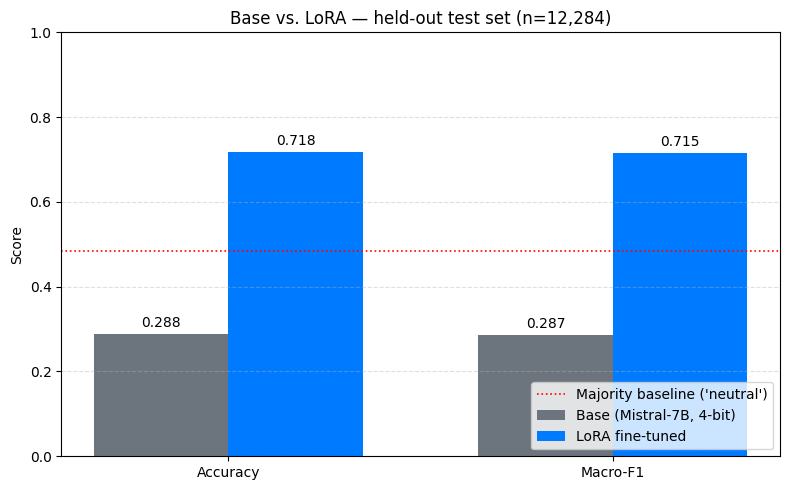


📊 Saved → lora_vs_base.png

--- Sample LoRA raw completions (first 5) ---
  [0] raw='neutral\n\n### Instruction:'  →  parsed='neutral'
  [1] raw='neutral\n\n### Instruction:'  →  parsed='neutral'
  [2] raw='neutral\n\n### Instruction:'  →  parsed='neutral'
  [3] raw='positive\n\n### Instruction:'  →  parsed='positive'
  [4] raw='neutral\n\n### Instruction:'  →  parsed='neutral'

--- Sample BASE raw completions (first 5) ---
  [0] raw="@user @user what do these '"  →  parsed='UNPARSED'
  [1] raw='The sentiment of the text is negative'  →  parsed='negative'
  [2] raw="@user @user That's"  →  parsed='UNPARSED'
  [3] raw='The text is positive.'  →  parsed='positive'
  [4] raw='The sentiment of the following text is'  →  parsed='UNPARSED'
💾 Saved → ./results/metrics_core.json

✅ Cell 5B complete


In [6]:
# =============================================================
# CELL 5B: Metrics, Reports, Chart  (uses ./lora_results.pkl)
# =============================================================
# Runtime: <10 seconds. Re-run freely — no re-inference needed.
# =============================================================
import pickle, json, os
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

# --- 1. Load saved results
with open("lora_results.pkl", "rb") as f:
    R = pickle.load(f)
y_true   = R["y_true"]
base_raw = R["base_raw"]
lora_raw = R["lora_raw"]
print(f"Loaded {len(y_true):,} results from ./lora_results.pkl")

# --- 2. Parser — handles all 3 classes
VALID = ["negative", "neutral", "positive"]

def parse_label(text: str) -> str:
    t = text.strip().lower()
    if not t:
        return "UNPARSED"
    first = t.split()[0].strip(".,!?;:'\"")
    if first in VALID:
        return first
    hits = [(t.find(w), w) for w in VALID if w in t]
    return min(hits)[1] if hits else "UNPARSED"

base_preds = [parse_label(c) for c in base_raw]
lora_preds = [parse_label(c) for c in lora_raw]

# --- 3. Sanity gates
#   ✅ base UNPARSED rate is EXPECTED to be high (completion model)
#   ✅ only LoRA UNPARSED rate is a real bug signal
assert len(base_preds) == len(lora_preds) == len(y_true), "Length mismatch"
assert len(set(y_true)) == 3, "Test labels are not 3-class"

n_unp_base = base_preds.count("UNPARSED")
n_unp_lora = lora_preds.count("UNPARSED")
pct_base   = 100 * n_unp_base / len(y_true)
pct_lora   = 100 * n_unp_lora / len(y_true)
print(f"\nUNPARSED — base: {n_unp_base} ({pct_base:.1f}%), "
      f"lora: {n_unp_lora} ({pct_lora:.1f}%)")
print("  (high base UNPARSED is EXPECTED — completion model, not instruct-tuned)")

assert pct_lora < 5.0, (
    f"LoRA unparsed {pct_lora:.1f}% — parser or adapter broken. "
    f"Sample: {lora_raw[:5]}"
)

n_diff = sum(b != l for b, l in zip(base_preds, lora_preds))
print(f"Predictions differing between base and LoRA: {n_diff}/{len(y_true)}")
assert n_diff > 0, "Base and LoRA identical — adapter disabled OR not trained"

# --- 4. Metrics
base_acc = accuracy_score(y_true, base_preds)
lora_acc = accuracy_score(y_true, lora_preds)
base_f1  = f1_score(y_true, base_preds, average="macro", zero_division=0)
lora_f1  = f1_score(y_true, lora_preds, average="macro", zero_division=0)

print("\n" + "=" * 60)
print(f"{'Metric':<18}{'Base':>10}{'LoRA':>10}{'Δ':>10}")
print("=" * 60)
print(f"{'Accuracy':<18}{base_acc:>10.4f}{lora_acc:>10.4f}{lora_acc - base_acc:>+10.4f}")
print(f"{'Macro-F1':<18}{base_f1:>10.4f}{lora_f1:>10.4f}{lora_f1 - base_f1:>+10.4f}")
print("=" * 60)

# --- 5. Class distribution + majority baseline
counts    = Counter(y_true)
maj_label = counts.most_common(1)[0][0]
maj_acc   = counts[maj_label] / len(y_true)
print(f"\nTest distribution: {dict(counts)}")
print(f"Majority baseline ('{maj_label}' always): "
      f"acc={maj_acc:.4f}  (base is {base_acc-maj_acc:+.4f} vs this)")

# --- 6. Per-class report + confusion matrix
print("\nPer-class report (LoRA):")
print(classification_report(y_true, lora_preds, labels=VALID,
                            zero_division=0, digits=4))

cm = confusion_matrix(y_true, lora_preds, labels=VALID)
print("Confusion matrix (rows=true, cols=pred):")
print(f"{'':<10}" + "".join(f"{l:>10}" for l in VALID))
for i, lab in enumerate(VALID):
    print(f"{lab:<10}" + "".join(f"{cm[i,j]:>10}" for j in range(len(VALID))))

# --- 7. Chart (with majority-baseline reference line)
fig, ax = plt.subplots(figsize=(8, 5))
metrics   = ["Accuracy", "Macro-F1"]
base_vals = [base_acc, base_f1]
lora_vals = [lora_acc, lora_f1]
x = np.arange(len(metrics)); w = 0.35
b1 = ax.bar(x-w/2, base_vals, w, label="Base (Mistral-7B, 4-bit)", color="#6c757d")
b2 = ax.bar(x+w/2, lora_vals, w, label="LoRA fine-tuned",         color="#007bff")
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.3f}", xy=(bar.get_x()+bar.get_width()/2, h),
                    xytext=(0,3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10)
ax.axhline(maj_acc, color="red", linestyle=":", linewidth=1.2,
           label=f"Majority baseline ('{maj_label}')")
ax.set_ylabel("Score")
ax.set_title(f"Base vs. LoRA — held-out test set (n={len(y_true):,})")
ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylim(0, 1.0)
ax.legend(loc="lower right"); ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("lora_vs_base.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n📊 Saved → lora_vs_base.png")

# --- 8. Sample completions (side-by-side)
print("\n--- Sample LoRA raw completions (first 5) ---")
for i, c in enumerate(lora_raw[:5]):
    print(f"  [{i}] raw={c!r}  →  parsed={parse_label(c)!r}")
print("\n--- Sample BASE raw completions (first 5) ---")
for i, c in enumerate(base_raw[:5]):
    print(f"  [{i}] raw={c!r}  →  parsed={parse_label(c)!r}")

# --- 9. Save core metrics for Cell 6 / 7
os.makedirs("results", exist_ok=True)
metrics_json = {
    "test_size": len(y_true),
    "distribution": dict(counts),
    "majority_baseline": {"label": maj_label, "accuracy": float(maj_acc)},
    "base": {"accuracy": float(base_acc), "macro_f1": float(base_f1),
             "unparsed_pct": float(pct_base)},
    "lora": {"accuracy": float(lora_acc), "macro_f1": float(lora_f1),
             "unparsed_pct": float(pct_lora)},
}
with open("results/metrics_core.json", "w") as f:
    json.dump(metrics_json, f, indent=2)
print("💾 Saved → ./results/metrics_core.json")

print("\n✅ Cell 5B complete")

# **Decomposition, Baseline Context & Artifacts**

In [7]:
# =============================================================
# CELL 6: Decomposition, Baseline Context & Artifacts
# =============================================================
import pickle, json, os
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score

# 1. Reload the raw results (we need the raw strings again)
with open("lora_results.pkl", "rb") as f:
    R = pickle.load(f)
y_true, base_raw, lora_raw = R["y_true"], R["base_raw"], R["lora_raw"]

# 2. Reparse (using the same parser from 5B)
VALID = ["negative", "neutral", "positive"]
def parse_label(text):
    t = text.strip().lower()
    if not t: return "UNPARSED"
    first = t.split()[0].strip(".,!?;:'\"")
    if first in VALID: return first
    hits = [(t.find(w), w) for w in VALID if w in t]
    return min(hits)[1] if hits else "UNPARSED"

base_preds = [parse_label(c) for c in base_raw]
lora_preds = [parse_label(c) for c in lora_raw]

# 3. Base Metrics
n = len(y_true)
base_acc = accuracy_score(y_true, base_preds)
lora_acc = accuracy_score(y_true, lora_preds)
base_f1  = f1_score(y_true, base_preds, average="macro", zero_division=0)
lora_f1  = f1_score(y_true, lora_preds, average="macro", zero_division=0)

# 4. Format Compliance (How often did the model produce a valid label?)
fmt_base = sum(p != "UNPARSED" for p in base_preds) / n
fmt_lora = sum(p != "UNPARSED" for p in lora_preds) / n

# 5. Fair Comparison (On examples the base model COULD parse)
mask = [p != "UNPARSED" for p in base_preds]
y_sub = [y_true[i] for i, m in enumerate(mask) if m]
b_sub = [base_preds[i] for i, m in enumerate(mask) if m]
l_sub = [lora_preds[i] for i, m in enumerate(mask) if m]
b_sub_acc = accuracy_score(y_sub, b_sub)
l_sub_acc = accuracy_score(y_sub, l_sub)

# 6. The Decomposition
# Format effect = (LoRA format rate - Base format rate) * Base accuracy-on-parsed
format_effect = (fmt_lora - fmt_base) * b_sub_acc
# Task effect = LoRA format rate * (LoRA accuracy-on-parsed - Base accuracy-on-parsed)
task_effect   = fmt_lora * (l_sub_acc - b_sub_acc)

# 7. Majority Baseline
counts = Counter(y_true)
maj_label = counts.most_common(1)[0][0]
maj_acc = counts[maj_label] / n
maj_f1 = f1_score(y_true, [maj_label]*n, average="macro", zero_division=0)

print("=" * 65)
print(" 🏆 FINAL RESULTS DECOMPOSITION")
print("=" * 65)
print(f"End-to-End Accuracy : {base_acc:.4f}  →  {lora_acc:.4f}   ({lora_acc-base_acc:+.4f})")
print(f"End-to-End Macro-F1 : {base_f1:.4f}  →  {lora_f1:.4f}   ({lora_f1-base_f1:+.4f})")
print("-" * 65)
print(f"Majority Baseline   : {maj_acc:.4f} (Always predicting '{maj_label}')")
print(f"  Base vs Baseline  : {base_acc - maj_acc:+.4f}  (Base is WORSE than a dummy)")
print(f"  LoRA vs Baseline  : {lora_acc - maj_acc:+.4f}  (LoRA is meaningfully better)")
print("-" * 65)
print(f"Format Compliance   : {fmt_base:.4f}  →  {fmt_lora:.4f}   ({fmt_lora-fmt_base:+.4f})")
print(f"Acc on Parseable Sub: {b_sub_acc:.4f}  →  {l_sub_acc:.4f}   ({l_sub_acc-b_sub_acc:+.4f})")
print("-" * 65)
print(" WHY DID ACCURACY INCREASE?")
print(f"  1. Format Effect (+{format_effect:.4f}): Base model rambled (no label).")
print(f"     LoRA learned to always output a valid label.")
print(f"  2. Task Effect   (+{task_effect:.4f}): LoRA actually got better at")
print(f"     classifying when both models produced a label.")
print(f"  TOTAL LIFT       : +{format_effect + task_effect:.4f}")
print("=" * 65)

# 8. Save all artifacts for GitHub
os.makedirs("results", exist_ok=True)
metrics = {
    "dataset": "cardiffnlp/tweet_eval/sentiment",
    "base_model": "unsloth/mistral-7b-bnb-4bit",
    "test_size": n,
    "distribution": dict(counts),
    "base": {
        "accuracy": round(base_acc, 4),
        "macro_f1": round(base_f1, 4),
        "format_compliance": round(fmt_base, 4)
    },
    "lora": {
        "accuracy": round(lora_acc, 4),
        "macro_f1": round(lora_f1, 4),
        "format_compliance": round(fmt_lora, 4)
    },
    "baseline": {"accuracy": round(maj_acc, 4), "macro_f1": round(maj_f1, 4)},
    "decomposition": {
        "format_effect": round(format_effect, 4),
        "task_effect": round(task_effect, 4),
        "total_lift": round(lora_acc - base_acc, 4)
    }
}
with open("results/final_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("\n✅ Cell 6 complete — final_metrics.json saved")

 🏆 FINAL RESULTS DECOMPOSITION
End-to-End Accuracy : 0.2879  →  0.7183   (+0.4305)
End-to-End Macro-F1 : 0.2868  →  0.7155   (+0.4287)
-----------------------------------------------------------------
Majority Baseline   : 0.4833 (Always predicting 'neutral')
  Base vs Baseline  : -0.1955  (Base is WORSE than a dummy)
  LoRA vs Baseline  : +0.2350  (LoRA is meaningfully better)
-----------------------------------------------------------------
Format Compliance   : 0.5183  →  1.0000   (+0.4817)
Acc on Parseable Sub: 0.5554  →  0.7149   (+0.1596)
-----------------------------------------------------------------
 WHY DID ACCURACY INCREASE?
  1. Format Effect (+0.2675): Base model rambled (no label).
     LoRA learned to always output a valid label.
  2. Task Effect   (+0.1596): LoRA actually got better at
     classifying when both models produced a label.
  TOTAL LIFT       : +0.4271

✅ Cell 6 complete — final_metrics.json saved


# **Download Artifacts**

In [9]:
# =============================================================
# CELL 7: Download Artifacts
# =============================================================
import os
import shutil
from google.colab import files

# 1. Download the chart (for README / LinkedIn)
if os.path.exists("lora_vs_base.png"):
    files.download("lora_vs_base.png")
    print("📥 Downloaded: lora_vs_base.png")
else:
    print("⚠️ lora_vs_base.png not found. Did Cell 5B run successfully?")

# 2. Download the metrics JSON (for README)
metrics_path = "results/final_metrics.json"
if os.path.exists(metrics_path):
    files.download(metrics_path)
    print("📥 Downloaded: final_metrics.json")
else:
    print("⚠️ final_metrics.json not found. Did Cell 6 run successfully?")

# 3. Zip and download the LoRA adapter weights (optional, but good for backups)
if os.path.exists("lora_adapter"):
    print("Zipping LoRA adapter...")
    shutil.make_archive("lora_adapter_weights", 'zip', ".", "lora_adapter")
    files.download("lora_adapter_weights.zip")
    print("📥 Downloaded: lora_adapter_weights.zip")
else:
    print("⚠️ lora_adapter folder not found. Did Cell 4 save the model?")

print("\n✅ Cell 7 complete — check your browser downloads!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📥 Downloaded: lora_vs_base.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📥 Downloaded: final_metrics.json
Zipping LoRA adapter...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📥 Downloaded: lora_adapter_weights.zip

✅ Cell 7 complete — check your browser downloads!
